# Lezione 04 — Caso TakeHome Docente

## Shortfall di margine condizionato a regimi del costo dell'energia

Il caso considera un'impresa manifatturiera energivora esposta all'incertezza del prezzo unitario dell'energia.

Le grandezze principali sono:

- $G_0$: contribuzione operativa netta non energetica;
- $Q_E$: fabbisogno energetico;
- $P_E$: prezzo unitario dell'energia;
- $C_E=Q_E P_E$: costo energetico totale;
- $M=G_0-Q_E P_E$: margine operativo dopo il costo energetico;
- $m^\star$: margine minimo desiderato;
- $S=(m^\star-M)^+$: shortfall di margine;
- $s^\star$: soglia di shortfall severo.

L'informazione disponibile distingue tre regimi:

- $A_1$: Normalizzazione energetica;
- $A_2$: Tensione persistente;
- $A_3$: Shock energetico severo.

La sigma-algebra informativa è

$$
\mathcal{G}=\sigma(A_1,A_2,A_3),
$$

e, condizionatamente al regime $A_g$,

$$
P_E\mid A_g\sim\mathcal{N}(\mu_g,\sigma_g^2),
\qquad g=1,2,3.
$$

La domanda quantitativa è:

> **Qual è la distribuzione dello shortfall di margine e come cambia lo shortfall atteso condizionando sui diversi regimi del costo dell'energia?**

Il caso è simulativo e didattico: non ha finalità previsionali sul prezzo dell'energia.

## Quantità da stimare

$$
\mathbb{E}[S],\qquad
\mathbb{P}(S>0),\qquad
\mathbb{P}(S>s^\star),\qquad
q_\alpha(S),
$$

e, per ciascun regime,

$$
\mathbb{E}[S\mid A_g].
$$

Il valore atteso condizionato rispetto all'informazione di regime è

$$
\mathbb{E}[S\mid\mathcal G]
=
\sum_{g=1}^{3}\mathbb{E}[S\mid A_g]\mathbf{1}_{A_g}.
$$

Deve inoltre essere verificata la formula del valore atteso totale:

$$
\mathbb{E}[S]
=
\sum_{g=1}^{3}
\mathbb{P}(A_g)\mathbb{E}[S\mid A_g].
$$


## Flusso logico-teorico risolutivo

| Passo | Finalità risolutiva | Oggetto teorico | Applicazione nel caso | Output / controllo |
|---:|---|---|---|---|
| 1 | Identificare la variabile economica finale e le soglie di rischio | $S=(m^\star-M)^+$, con $M=G_0-Q_E P_E$; eventi $\{S>0\}$ e $\{S>s^\star\}$ | Lo shortfall dipende dal prezzo dell'energia tramite costo e margine; le soglie monetarie diventano soglie implicite su $P_E$ | Controllo $S\ge 0$; soglie $P_E>120$ e $P_E>140$ |
| 2 | Rappresentare l'informazione e il comportamento del prezzo nei diversi regimi | Partizione $A_1,A_2,A_3$; $\mathcal G=\sigma(A_1,A_2,A_3)$; $P_E\mid A_g\sim\mathcal N(\mu_g,\sigma_g^2)$ | Le probabilità dei regimi guidano l'estrazione Monte Carlo e ogni regime determina una diversa distribuzione del prezzo | Frequenze empiriche; controllo di media e deviazione standard di $P_E\mid A_g$; eventuali $P_E<0$ |
| 3 | Costruire la distribuzione non condizionata del prezzo | Campionamento gerarchico: prima $A_g$, poi $P_E\mid A_g$ | La distribuzione globale di $P_E$ nasce dalla miscela delle distribuzioni condizionate | Dataset simulato con evento e $P_E$; distribuzione empirica di $P_E$ |
| 4 | Trasformare il prezzo in costo, margine e shortfall | $C_E=Q_EP_E$, $M=G_0-Q_EP_E$, $S=(m^\star-M)^+$ | Ogni prezzo simulato genera le grandezze economiche rilevanti | Dataset con $P_E$, $C_E$, $M$, $S$; controlli formula-codice |
| 5 | Produrre la lettura non condizionata del rischio | Distribuzione empirica, media, quantili, probabilità di superamento soglia | Si analizzano globalmente $P_E$, $M$ e $S$ senza distinguere i regimi | Statistiche descrittive; $\widehat{\mathbb E}[S]$; $\widehat{\mathbb P}(S>0)$; $\widehat{\mathbb P}(S>s^\star)$; grafici globali |
| 6 | Produrre la lettura condizionata per regime | $\mathbb E[S\mid A_g]$ | Si confronta lo shortfall atteso nei tre regimi energetici | Tabella e grafico delle medie condizionate; confronto delle distribuzioni condizionate |
| 7 | Collegare l'informazione disponibile alla previsione condizionata | $\mathbb E[S\mid\mathcal G]=\sum_g \mathbb E[S\mid A_g]\mathbf 1_{A_g}$ | La previsione condizionata è una variabile casuale costante sui blocchi della partizione | Colonna empirica $\widehat{\mathbb E}[S\mid\mathcal G]$; distinzione tra numero e variabile casuale |
| 8 | Verificare la coerenza complessiva e interpretare il ruolo dell'informazione | $\mathbb E[S]=\sum_g\mathbb P(A_g)\mathbb E[S\mid A_g]$ | La media globale viene ricostruita come media pesata delle medie di regime; l'informazione modifica la distribuzione rilevante ma non elimina l'incertezza | Verifica del valore atteso totale; controlli conclusivi; interpretazione e limiti |


## Scomposizione operativa in tappe

| Tappa | Titolo | Input | Operazione | Output | Controllo |
|---:|---|---|---|---|---|
| 1 | Specifica teorica e parametri | $G_0,Q_E,m^\star,s^\star,n$, seed, probabilità e parametri condizionati | Definizione degli oggetti e delle soglie | Tabelle dei parametri | Somma probabilità; soglie 120 e 140 |
| 2 | Simulazione della partizione informativa | Probabilità dei regimi, $n$, seed | Estrazione delle etichette $A_1,A_2,A_3$ | Frequenze empiriche | Ammissibilità etichette e coerenza frequenze |
| 3 | Simulazione di $P_E\mid A_g$, costo, margine e shortfall | Regimi simulati e parametri | Simulazione prezzi e trasformazioni economiche | Dataset principale | Dimensioni, momenti, $P_E<0$, formule e parte positiva |
| 4 | Analisi non condizionata | Dataset, soglie | Statistiche, quantili, probabilità e grafici | Tabelle e grafici globali | Quantili, probabilità, massa in zero |
| 5 | Analisi condizionata e valore atteso totale | Evento e $S$ | Medie condizionate, distribuzioni per regime e ricomposizione | Tabelle e grafici condizionati | Ordine delle medie e media ricomposta |
| 6 | Controlli conclusivi, interpretazione e limiti | Tutti gli output | Verifica complessiva | Quadro dei controlli e discussione finale | Coerenza teorica, numerica e interpretativa |


## Tappa 1 — Specifica teorica e parametri

### Obiettivo

Tradurre la specifica del caso in parametri economico-finanziari e probabilistici, senza modificarne la struttura.

Le soglie implicite sono:

$$
S>0
\Longleftrightarrow
P_E>\frac{G_0-m^\star}{Q_E}=120,
$$

e

$$
S>s^\star
\Longleftrightarrow
P_E>\frac{G_0-m^\star+s^\star}{Q_E}=140.
$$


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.precision", 6)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.6f}")

def stile_tabella(df, formati):
    """Restituisce una copia di sola visualizzazione con formati leggibili."""
    vista = df.copy()
    for colonna, formato in formati.items():
        if colonna in vista.columns:
            vista[colonna] = vista[colonna].map(
                lambda x, formato=formato: "" if pd.isna(x) else formato.format(x)
            )
    return vista

seed = 24680
rng = np.random.default_rng(seed)

G0 = 8_000_000.0
Q_E = 50_000.0
m_star = 2_000_000.0
s_star = 1_000_000.0
n = 50_000

eventi = np.array(["A1", "A2", "A3"])
descrizioni = {
    "A1": "Normalizzazione energetica",
    "A2": "Tensione persistente",
    "A3": "Shock energetico severo",
}
lettura_economica = {
    "A1": "prezzi relativamente contenuti",
    "A2": "prezzi elevati ma non estremi",
    "A3": "prezzi molto elevati e piu' volatili",
}
p = np.array([0.35, 0.45, 0.20])
mu = np.array([75.0, 115.0, 170.0])
sigma = np.array([15.0, 25.0, 45.0])

assert n > 0
assert G0 > 0 and Q_E > 0 and m_star > 0 and s_star > 0
assert np.isclose(p.sum(), 1.0)
assert np.all(p > 0)
assert np.all(sigma > 0)

p_star_shortfall = (G0 - m_star) / Q_E
p_star_severo = (G0 - m_star + s_star) / Q_E

assert np.isclose(p_star_shortfall, 120.0)
assert np.isclose(p_star_severo, 140.0)

df_parametri = pd.DataFrame({
    "grandezza": ["G0", "Q_E", "m_star", "s_star", "n", "seed"],
    "valore": [G0, Q_E, m_star, s_star, n, seed],
    "unita": ["euro", "MWh", "euro", "euro", "simulazioni", "-"],
})

df_eventi = pd.DataFrame({
    "evento": eventi,
    "descrizione": [descrizioni[e] for e in eventi],
    "probabilita_teorica": p,
    "lettura_economica": [lettura_economica[e] for e in eventi],
})

df_parametri_condizionati = pd.DataFrame({
    "evento": eventi,
    "mu_g": mu,
    "sigma_g": sigma,
    "unita": "euro/MWh",
})

df_soglie = pd.DataFrame({
    "condizione": ["S > 0", "S > s_star"],
    "soglia_PE_euro_MWh": [p_star_shortfall, p_star_severo],
})

display(stile_tabella(df_parametri, {"valore": "{:,.2f}"}))
display(stile_tabella(df_eventi, {"probabilita_teorica": "{:.4f}"}))
display(stile_tabella(df_parametri_condizionati, {"mu_g": "{:.2f}", "sigma_g": "{:.2f}"}))
display(stile_tabella(df_soglie, {"soglia_PE_euro_MWh": "{:.2f}"}))

,grandezza,valore,unita
0,G0,"8,000,000.00",euro
1,Q_E,"50,000.00",MWh
2,m_star,"2,000,000.00",euro
3,s_star,"1,000,000.00",euro
4,n,"50,000.00",simulazioni
5,seed,"24,680.00",-


,evento,descrizione,probabilita_teorica,lettura_economica
0,A1,Normalizzazione energetica,0.3500,prezzi relativamente contenuti
1,A2,Tensione persistente,0.4500,prezzi elevati ma non estremi
2,A3,Shock energetico severo,0.2000,prezzi molto elevati e piu' volatili


,evento,mu_g,sigma_g,unita
0,A1,75.00,15.00,euro/MWh
1,A2,115.00,25.00,euro/MWh
2,A3,170.00,45.00,euro/MWh


,condizione,soglia_PE_euro_MWh
0,S > 0,120.00
1,S > s_star,140.00


## Tappa 2 — Simulazione della partizione informativa

### Obiettivo

Assegnare ciascuna delle $n$ simulazioni a uno e un solo evento $A_g$ secondo le probabilità teoriche assegnate.

L'etichetta del regime è un oggetto operativo del dataset; non viene introdotta una nuova variabile casuale teorica nel modello.


In [2]:
evento_simulato = rng.choice(eventi, size=n, p=p)

df_frequenze = (
    pd.Series(evento_simulato, name="evento")
    .value_counts()
    .reindex(eventi)
    .rename("frequenza")
    .reset_index()
)
df_frequenze["frequenza_relativa"] = df_frequenze["frequenza"] / n
df_frequenze["probabilita_teorica"] = p
df_frequenze["scarto"] = df_frequenze["frequenza_relativa"] - df_frequenze["probabilita_teorica"]
df_frequenze["tolleranza_3_sigma"] = 3 * np.sqrt(p * (1 - p) / n)
df_frequenze["entro_tolleranza"] = (
    df_frequenze["scarto"].abs() <= df_frequenze["tolleranza_3_sigma"]
)

assert len(evento_simulato) == n
assert set(np.unique(evento_simulato)).issubset(set(eventi))
assert (df_frequenze["frequenza"] > 0).all()

stile_tabella(
    df_frequenze,
    {
        "frequenza": "{:,.0f}",
        "frequenza_relativa": "{:.4f}",
        "probabilita_teorica": "{:.4f}",
        "scarto": "{:+.4f}",
        "tolleranza_3_sigma": "{:.4f}",
    },
)

,evento,frequenza,frequenza_relativa,probabilita_teorica,scarto,tolleranza_3_sigma,entro_tolleranza
0,A1,"17,498",0.3500,0.3500,-0.0000,0.0064,True
1,A2,"22,506",0.4501,0.4500,+0.0001,0.0067,True
2,A3,"9,996",0.1999,0.2000,-0.0001,0.0054,True


## Tappa 3 — Simulazione del prezzo dell'energia

Condizionatamente al regime simulato,

$$
P_E\mid A_g\sim\mathcal N(\mu_g,\sigma_g^2).
$$

La distribuzione globale di $P_E$ deriva quindi dal campionamento gerarchico: prima si estrae il regime, poi il prezzo condizionato a quel regime.

La specificazione normale può generare prezzi negativi. Tali valori, se presenti, devono essere rilevati e interpretati come limite del modello; non vengono eliminati.


In [3]:
param_map = df_parametri_condizionati.set_index("evento")[["mu_g", "sigma_g"]]

P_E = np.empty(n)
for evento in eventi:
    mask = evento_simulato == evento
    P_E[mask] = rng.normal(
        loc=param_map.loc[evento, "mu_g"],
        scale=param_map.loc[evento, "sigma_g"],
        size=mask.sum(),
    )

df = pd.DataFrame({
    "evento": evento_simulato,
    "descrizione_evento": pd.Series(evento_simulato).map(descrizioni),
    "P_E": P_E,
})

df_controllo_prezzi = (
    df.groupby("evento", observed=False)
    .agg(
        numerosita=("P_E", "size"),
        media_PE_empirica=("P_E", "mean"),
        sd_PE_empirica=("P_E", "std"),
        min_PE=("P_E", "min"),
    )
    .reindex(eventi)
    .reset_index()
    .merge(df_parametri_condizionati[["evento", "mu_g", "sigma_g"]], on="evento")
)
df_controllo_prezzi["scarto_media"] = (
    df_controllo_prezzi["media_PE_empirica"] - df_controllo_prezzi["mu_g"]
)
df_controllo_prezzi["scarto_sd"] = (
    df_controllo_prezzi["sd_PE_empirica"] - df_controllo_prezzi["sigma_g"]
)
df_controllo_prezzi["tol_media_3sigma"] = (
    3 * df_controllo_prezzi["sigma_g"] / np.sqrt(df_controllo_prezzi["numerosita"])
)
df_controllo_prezzi["tol_sd_3sigma"] = (
    3 * df_controllo_prezzi["sigma_g"]
    / np.sqrt(2 * (df_controllo_prezzi["numerosita"] - 1))
)
df_controllo_prezzi["media_coerente"] = (
    df_controllo_prezzi["scarto_media"].abs()
    <= df_controllo_prezzi["tol_media_3sigma"]
)
df_controllo_prezzi["sd_coerente"] = (
    df_controllo_prezzi["scarto_sd"].abs()
    <= df_controllo_prezzi["tol_sd_3sigma"]
)

n_prezzi_negativi = int((df["P_E"] < 0).sum())
quota_prezzi_negativi = n_prezzi_negativi / n

display(stile_tabella(
    df_controllo_prezzi,
    {
        "numerosita": "{:,.0f}",
        "media_PE_empirica": "{:.3f}",
        "sd_PE_empirica": "{:.3f}",
        "min_PE": "{:.3f}",
        "mu_g": "{:.3f}",
        "sigma_g": "{:.3f}",
        "scarto_media": "{:+.3f}",
        "scarto_sd": "{:+.3f}",
    },
))
print(f"Prezzi negativi simulati: {n_prezzi_negativi:,} ({quota_prezzi_negativi:.4%})")

,evento,numerosita,media_PE_empirica,sd_PE_empirica,min_PE,mu_g,sigma_g,scarto_media,scarto_sd,tol_media_3sigma,tol_sd_3sigma,media_coerente,sd_coerente
0,A1,"17,498",74.879,15.101,8.544,75.000,15.000,-0.121,+0.101,0.340187,0.240556,True,True
1,A2,"22,506",114.981,24.910,11.859,115.000,25.000,-0.019,-0.090,0.499933,0.353514,True,True
2,A3,"9,996",170.335,44.649,-8.423,170.000,45.000,+0.335,-0.351,1.350270,0.954833,True,True


Prezzi negativi simulati: 2 (0.0040%)


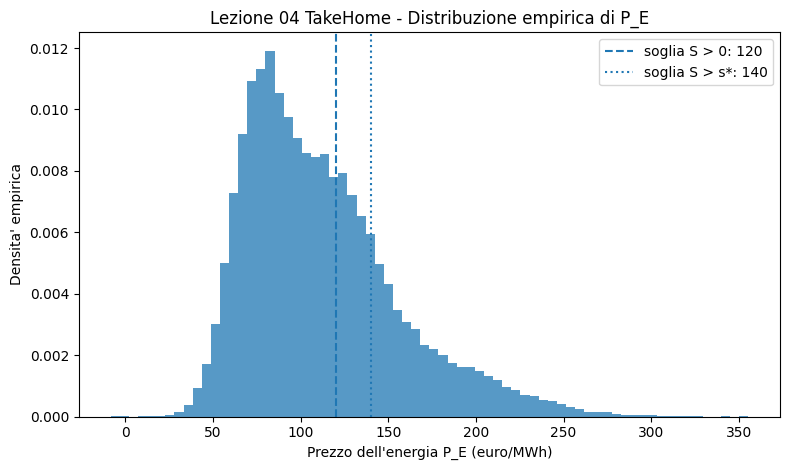

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.hist(df["P_E"], bins=70, density=True, alpha=0.75)
ax.axvline(p_star_shortfall, linestyle="--", label="soglia S > 0: 120")
ax.axvline(p_star_severo, linestyle=":", label="soglia S > s*: 140")
ax.set_xlabel("Prezzo dell'energia P_E (euro/MWh)")
ax.set_ylabel("Densita' empirica")
ax.set_title("Lezione 04 TakeHome - Distribuzione empirica di P_E")
ax.legend()
fig.tight_layout()
plt.show()

## Tappa 3 — Calcolo del costo energetico, del margine e dello shortfall

Per ogni osservazione simulata:

$$
C_E=Q_E P_E,
$$

$$
M=G_0-Q_E P_E,
$$

$$
S=(m^\star-M)^+
=
\max\{m^\star-M,0\}.
$$

La parte positiva rende $S$ una trasformazione non lineare del margine e genera una massa di probabilità in zero.


In [5]:
df["C_E"] = Q_E * df["P_E"]
df["M"] = G0 - df["C_E"]
df["S"] = np.maximum(m_star - df["M"], 0.0)

assert len(df) == n
assert np.allclose(df["C_E"], Q_E * df["P_E"])
assert np.allclose(df["M"], G0 - Q_E * df["P_E"])
assert (df["S"] >= 0).all()
assert np.allclose(df.loc[df["M"] >= m_star, "S"], 0.0)
assert np.allclose(
    df.loc[df["M"] < m_star, "S"],
    m_star - df.loc[df["M"] < m_star, "M"],
)

display(stile_tabella(
    df.head(),
    {
        "P_E": "{:.3f}",
        "C_E": "{:,.0f}",
        "M": "{:,.0f}",
        "S": "{:,.0f}",
    },
))

,evento,descrizione_evento,P_E,C_E,M,S
0,A2,Tensione persistente,119.034,"5,951,692","2,048,308",0
1,A2,Tensione persistente,129.679,"6,483,936","1,516,064","483,936"
2,A1,Normalizzazione energetica,66.562,"3,328,099","4,671,901",0
3,A2,Tensione persistente,102.019,"5,100,928","2,899,072",0
4,A1,Normalizzazione energetica,82.273,"4,113,666","3,886,334",0


## Tappa 4 — Analisi non condizionata dello shortfall

L'analisi globale non distingue i regimi. Si descrivono congiuntamente:

- il prezzo dell'energia $P_E$;
- il margine operativo $M$;
- lo shortfall $S$;
- la probabilità di shortfall positivo;
- la probabilità di shortfall severo;
- i principali quantili dello shortfall.

La massa in zero di $S$ rappresenta gli scenari in cui il margine non scende sotto $m^\star$.


In [6]:
quantili = [0.05, 0.25, 0.50, 0.75, 0.95, 0.99]

righe_descrittive = []
for col in ["P_E", "M", "S"]:
    serie = df[col]
    riga = {
        "grandezza": col,
        "media": serie.mean(),
        "deviazione_standard": serie.std(),
        "minimo": serie.min(),
        "massimo": serie.max(),
    }
    for q in quantili:
        riga[f"q{int(q*100):02d}"] = serie.quantile(q)
    righe_descrittive.append(riga)

df_descrittiva = pd.DataFrame(righe_descrittive)

prob_S_pos = (df["S"] > 0).mean()
prob_S_severo = (df["S"] > s_star).mean()
prob_PE_120 = (df["P_E"] > p_star_shortfall).mean()
prob_PE_140 = (df["P_E"] > p_star_severo).mean()
massa_zero = (df["S"] == 0).mean()

df_rischio = pd.DataFrame({
    "quantita": [
        "E_hat[S]",
        "P_hat(S > 0)",
        "P_hat(S > s_star)",
        "massa empirica in S = 0",
        "q95(S)",
        "q99(S)",
    ],
    "valore": [
        df["S"].mean(),
        prob_S_pos,
        prob_S_severo,
        massa_zero,
        df["S"].quantile(0.95),
        df["S"].quantile(0.99),
    ],
})

qS = df["S"].quantile(quantili).to_numpy()
assert np.all(np.diff(qS) >= 0)
assert df["S"].min() <= df["S"].mean() <= df["S"].max()
assert np.isclose(prob_S_pos, prob_PE_120)
assert np.isclose(prob_S_severo, prob_PE_140)
assert 0 <= prob_S_pos <= 1
assert 0 <= prob_S_severo <= 1

display(stile_tabella(
    df_descrittiva,
    {c: "{:,.3f}" for c in df_descrittiva.columns if c != "grandezza"},
))
display(stile_tabella(df_rischio, {"valore": "{:,.6f}"}))
print(f"P_hat(S > 0)       = {prob_S_pos:.4f}")
print(f"P_hat(S > s*)      = {prob_S_severo:.4f}")
print(f"Massa empirica S=0 = {massa_zero:.4f}")

,grandezza,media,deviazione_standard,minimo,massimo,q05,q25,q50,q75,q95,q99
0,P_E,112.013,43.866,-8.423,355.329,57.700,79.120,103.687,135.490,200.713,244.078
1,M,"2,399,337.463","2,193,278.821","-9,766,449.514","8,421,165.853","-2,035,651.554","1,225,515.253","2,815,630.062","4,044,022.512","5,114,994.545","5,755,888.809"
2,S,"704,845.357","1,399,558.015",0.000,"11,766,449.514",0.000,0.000,0.000,"774,484.747","4,035,651.554","6,203,896.401"


,quantita,valore
0,E_hat[S],"704,845.356688"
1,P_hat(S > 0),0.363260
2,P_hat(S > s_star),0.221640
3,massa empirica in S = 0,0.636740
4,q95(S),"4,035,651.553548"
5,q99(S),"6,203,896.400561"


P_hat(S > 0)       = 0.3633
P_hat(S > s*)      = 0.2216
Massa empirica S=0 = 0.6367


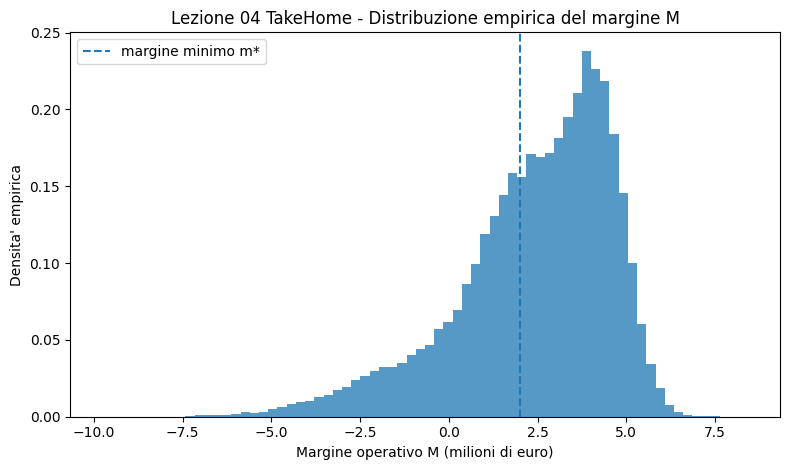

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.hist(df["M"] / 1_000_000, bins=70, density=True, alpha=0.75)
ax.axvline(m_star / 1_000_000, linestyle="--", label="margine minimo m*")
ax.set_xlabel("Margine operativo M (milioni di euro)")
ax.set_ylabel("Densita' empirica")
ax.set_title("Lezione 04 TakeHome - Distribuzione empirica del margine M")
ax.legend()
fig.tight_layout()
plt.show()

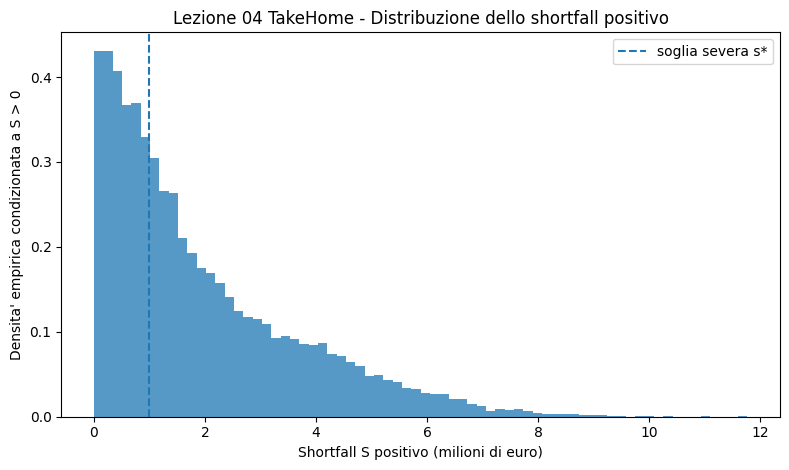

La massa in zero non e' visibile in questo istogramma dei soli valori positivi; la sua quota empirica e' 63.67%.


In [8]:
fig, ax = plt.subplots(figsize=(8, 4.8))
S_positivi = df.loc[df["S"] > 0, "S"] / 1_000_000
ax.hist(S_positivi, bins=70, density=True, alpha=0.75)
ax.axvline(s_star / 1_000_000, linestyle="--", label="soglia severa s*")
ax.set_xlabel("Shortfall S positivo (milioni di euro)")
ax.set_ylabel("Densita' empirica condizionata a S > 0")
ax.set_title("Lezione 04 TakeHome - Distribuzione dello shortfall positivo")
ax.legend()
fig.tight_layout()
plt.show()

print(
    "La massa in zero non e' visibile in questo istogramma dei soli valori positivi; "
    f"la sua quota empirica e' {massa_zero:.2%}."
)

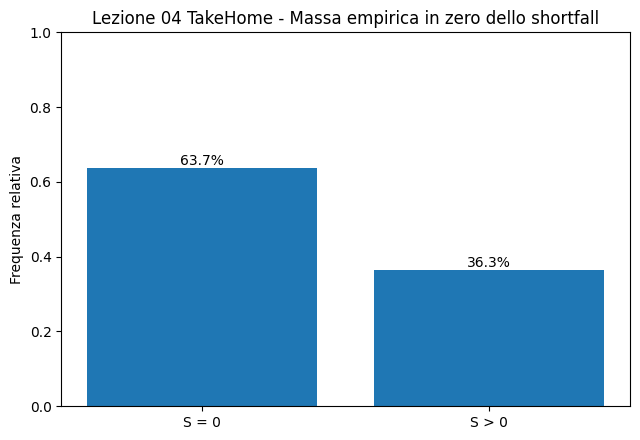

In [9]:
df_massa_zero = pd.DataFrame({
    "stato": ["S = 0", "S > 0"],
    "frequenza_relativa": [massa_zero, 1 - massa_zero],
})

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.bar(df_massa_zero["stato"], df_massa_zero["frequenza_relativa"])
ax.set_ylabel("Frequenza relativa")
ax.set_title("Lezione 04 TakeHome - Massa empirica in zero dello shortfall")
ax.set_ylim(0, 1)
for i, v in enumerate(df_massa_zero["frequenza_relativa"]):
    ax.text(i, v, f"{v:.1%}", ha="center", va="bottom")
fig.tight_layout()
plt.show()

## Tappa 5 — Analisi condizionata per evento

Per ciascun regime si stima

$$
\widehat{\mathbb E}[S\mid A_g].
$$

Il confronto deve mantenere distinta:

- la media condizionata $\mathbb E[S\mid A_g]$, che è un numero;
- la variabile casuale $\mathbb E[S\mid\mathcal G]$, costante su ciascun blocco della partizione;
- la media globale $\mathbb E[S]$.

La calibrazione del caso richiede un ordinamento economicamente leggibile: $A_1$ con shortfall atteso più basso, $A_2$ intermedio, $A_3$ più elevato.


In [10]:
df_cond = (
    df.groupby("evento", observed=False)
    .agg(
        frequenza=("S", "size"),
        E_hat_S_cond=("S", "mean"),
        sd_S_cond=("S", "std"),
        prob_S_pos_cond=("S", lambda x: (x > 0).mean()),
        prob_S_severo_cond=("S", lambda x: (x > s_star).mean()),
        q50_S_cond=("S", lambda x: x.quantile(0.50)),
        q95_S_cond=("S", lambda x: x.quantile(0.95)),
    )
    .reindex(eventi)
    .reset_index()
)
df_cond["frequenza_relativa"] = df_cond["frequenza"] / n
df_cond["descrizione"] = df_cond["evento"].map(descrizioni)
df_cond["ordine_atteso"] = df_cond["evento"].map({"A1": 1, "A2": 2, "A3": 3})

assert (df_cond["frequenza"] > 0).all()
assert df_cond.sort_values("ordine_atteso")["E_hat_S_cond"].is_monotonic_increasing

display(stile_tabella(
    df_cond,
    {
        "frequenza": "{:,.0f}",
        "E_hat_S_cond": "{:,.0f}",
        "sd_S_cond": "{:,.0f}",
        "prob_S_pos_cond": "{:.4f}",
        "prob_S_severo_cond": "{:.4f}",
        "q50_S_cond": "{:,.0f}",
        "q95_S_cond": "{:,.0f}",
        "frequenza_relativa": "{:.4f}",
    },
))

,evento,frequenza,E_hat_S_cond,sd_S_cond,prob_S_pos_cond,prob_S_severo_cond,q50_S_cond,q95_S_cond,frequenza_relativa,descrizione,ordine_atteso
0,A1,"17,498",406,"13,183",0.0017,0.0001,0,0,0.3500,Normalizzazione energetica,1
1,A2,"22,506","382,217","639,766",0.4207,0.1583,0,"1,800,126",0.4501,Tensione persistente,2
2,A3,"9,996","2,664,366","1,983,277",0.8669,0.7521,"2,528,039","6,204,045",0.1999,Shock energetico severo,3


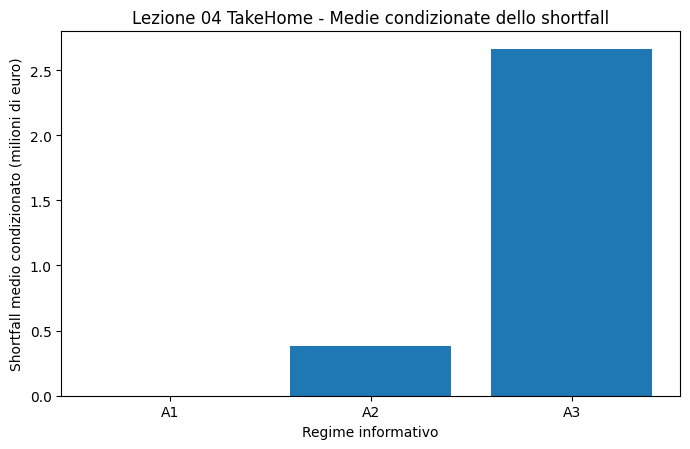

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.bar(df_cond["evento"], df_cond["E_hat_S_cond"] / 1_000_000)
ax.set_xlabel("Regime informativo")
ax.set_ylabel("Shortfall medio condizionato (milioni di euro)")
ax.set_title("Lezione 04 TakeHome - Medie condizionate dello shortfall")
fig.tight_layout()
plt.show()

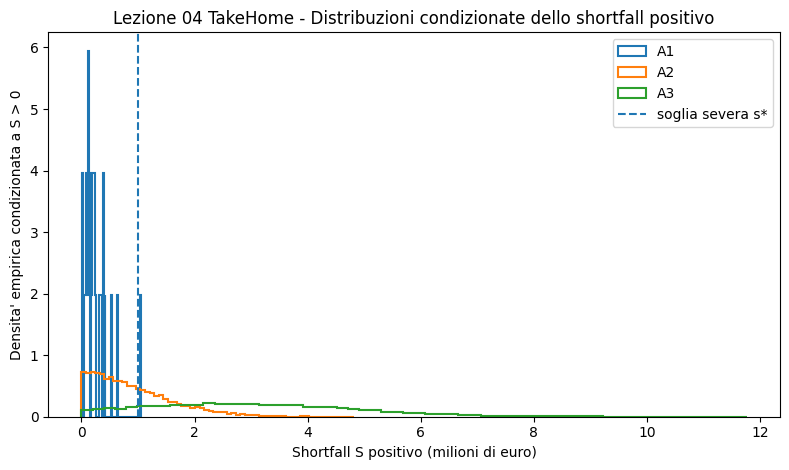

,evento,quota_S_zero
0,A1,0.9983
1,A2,0.5793
2,A3,0.1331


In [12]:
fig, ax = plt.subplots(figsize=(8, 4.8))
for evento in eventi:
    valori = df.loc[(df["evento"] == evento) & (df["S"] > 0), "S"] / 1_000_000
    ax.hist(
        valori,
        bins=60,
        density=True,
        histtype="step",
        linewidth=1.5,
        label=evento,
    )
ax.axvline(s_star / 1_000_000, linestyle="--", label="soglia severa s*")
ax.set_xlabel("Shortfall S positivo (milioni di euro)")
ax.set_ylabel("Densita' empirica condizionata a S > 0")
ax.set_title("Lezione 04 TakeHome - Distribuzioni condizionate dello shortfall positivo")
ax.legend()
fig.tight_layout()
plt.show()

df_zero_regime = (
    df.assign(S_zero=df["S"] == 0)
    .groupby("evento", observed=False)["S_zero"]
    .mean()
    .reindex(eventi)
    .rename("quota_S_zero")
    .reset_index()
)
display(stile_tabella(df_zero_regime, {"quota_S_zero": "{:.4f}"}))

## Tappa 5 — Valore atteso condizionato rispetto a $\mathcal G$ e valore atteso totale

La controparte empirica della variabile a gradini

$$
\mathbb E[S\mid\mathcal G]
=
\sum_g \mathbb E[S\mid A_g]\mathbf 1_{A_g}
$$

si ottiene associando a ogni osservazione la media empirica del regime cui appartiene.

La ricomposizione campionaria usa le frequenze empiriche:

$$
\widehat{\mathbb E}[S]
=
\sum_g
\widehat{\mathbb P}(A_g)
\widehat{\mathbb E}[S\mid A_g].
$$

Questa uguaglianza campionaria va distinta dalla proprietà teorica formulata con le probabilità del modello.


In [13]:
cond_map = df_cond.set_index("evento")["E_hat_S_cond"]
df["E_S_cond_G_hat"] = df["evento"].map(cond_map)

media_globale = df["S"].mean()
media_ricomposta_emp = (
    df_cond["frequenza_relativa"] * df_cond["E_hat_S_cond"]
).sum()
differenza_media = media_globale - media_ricomposta_emp

df_verifica_totale = pd.DataFrame({
    "quantita": [
        "media campionaria globale",
        "media ricomposta con frequenze empiriche",
        "differenza",
    ],
    "valore": [
        media_globale,
        media_ricomposta_emp,
        differenza_media,
    ],
})

assert np.isclose(media_globale, media_ricomposta_emp)
assert df.groupby("evento")["E_S_cond_G_hat"].nunique().max() == 1

display(stile_tabella(df_verifica_totale, {"valore": "{:,.6f}"}))
display(stile_tabella(
    df[["evento", "P_E", "C_E", "M", "S", "E_S_cond_G_hat"]].head(10),
    {
        "P_E": "{:.3f}",
        "C_E": "{:,.0f}",
        "M": "{:,.0f}",
        "S": "{:,.0f}",
        "E_S_cond_G_hat": "{:,.0f}",
    },
))

,quantita,valore
0,media campionaria globale,"704,845.356688"
1,media ricomposta con frequenze empiriche,"704,845.356688"
2,differenza,0.000000


,evento,P_E,C_E,M,S,E_S_cond_G_hat
0,A2,119.034,"5,951,692","2,048,308",0,"382,217"
1,A2,129.679,"6,483,936","1,516,064","483,936","382,217"
2,A1,66.562,"3,328,099","4,671,901",0,406
3,A2,102.019,"5,100,928","2,899,072",0,"382,217"
4,A1,82.273,"4,113,666","3,886,334",0,406
5,A2,103.079,"5,153,930","2,846,070",0,"382,217"
6,A2,72.600,"3,629,978","4,370,022",0,"382,217"
7,A1,65.402,"3,270,119","4,729,881",0,406
8,A2,106.796,"5,339,806","2,660,194",0,"382,217"
9,A2,107.810,"5,390,509","2,609,491",0,"382,217"


## Tappa 6 — Controlli conclusivi e predisposizione dell'interpretazione

La verifica conclusiva controlla che:

1. le probabilità dei regimi sommino a uno;
2. le frequenze empiriche siano compatibili con le probabilità teoriche;
3. i momenti empirici di $P_E\mid A_g$ siano coerenti con i parametri assegnati;
4. eventuali prezzi negativi siano rilevati;
5. le relazioni $C_E=Q_EP_E$, $M=G_0-Q_EP_E$ e $S=(m^\star-M)^+$ siano rispettate;
6. lo shortfall sia non negativo;
7. le equivalenze $S>0\Longleftrightarrow P_E>120$ e $S>s^\star\Longleftrightarrow P_E>140$ siano rispettate;
8. i quantili siano ordinati e la media sia compresa tra minimo e massimo;
9. le medie condizionate siano ordinate coerentemente con la calibrazione;
10. $\widehat{\mathbb E}[S\mid\mathcal G]$ sia costante sui blocchi;
11. la media globale coincida con la ricomposizione mediante frequenze empiriche.


In [14]:
controlli_conclusivi = [
    {
        "controllo": "Le probabilita' dei regimi sommano a 1",
        "superato": np.isclose(p.sum(), 1.0),
    },
    {
        "controllo": "Le frequenze empiriche dei regimi sono entro la tolleranza Monte Carlo",
        "superato": df_frequenze["entro_tolleranza"].all(),
    },
    {
        "controllo": "Ogni regime ha numerosita' positiva",
        "superato": (df_frequenze["frequenza"] > 0).all(),
    },
    {
        "controllo": "Media e deviazione standard empiriche di P_E sono coerenti con i parametri condizionati",
        "superato": (
            df_controllo_prezzi["media_coerente"].all()
            and df_controllo_prezzi["sd_coerente"].all()
        ),
    },
    {
        "controllo": "L'eventuale presenza di P_E < 0 e' stata rilevata",
        "superato": isinstance(n_prezzi_negativi, int),
    },
    {
        "controllo": "Il dataset contiene n osservazioni",
        "superato": len(df) == n,
    },
    {
        "controllo": "La relazione C_E = Q_E P_E e' rispettata",
        "superato": np.allclose(df["C_E"], Q_E * df["P_E"]),
    },
    {
        "controllo": "La relazione M = G0 - Q_E P_E e' rispettata",
        "superato": np.allclose(df["M"], G0 - Q_E * df["P_E"]),
    },
    {
        "controllo": "Lo shortfall S e' sempre non negativo",
        "superato": (df["S"] >= 0).all(),
    },
    {
        "controllo": "S = 0 quando M >= m_star",
        "superato": np.allclose(df.loc[df["M"] >= m_star, "S"], 0.0),
    },
    {
        "controllo": "S = m_star - M quando M < m_star",
        "superato": np.allclose(
            df.loc[df["M"] < m_star, "S"],
            m_star - df.loc[df["M"] < m_star, "M"],
        ),
    },
    {
        "controllo": "S > 0 equivale a P_E > 120",
        "superato": (
            (df["S"] > 0).to_numpy()
            == (df["P_E"] > p_star_shortfall).to_numpy()
        ).all(),
    },
    {
        "controllo": "S > s_star equivale a P_E > 140",
        "superato": (
            (df["S"] > s_star).to_numpy()
            == (df["P_E"] > p_star_severo).to_numpy()
        ).all(),
    },
    {
        "controllo": "I quantili empirici dello shortfall sono ordinati",
        "superato": np.all(np.diff(qS) >= 0),
    },
    {
        "controllo": "La media dello shortfall e' compresa tra minimo e massimo",
        "superato": df["S"].min() <= df["S"].mean() <= df["S"].max(),
    },
    {
        "controllo": "Le medie condizionate sono ordinate A1 < A2 < A3",
        "superato": df_cond.sort_values("ordine_atteso")["E_hat_S_cond"].is_monotonic_increasing,
    },
    {
        "controllo": "E[S|G] stimato e' costante su ciascun blocco",
        "superato": df.groupby("evento")["E_S_cond_G_hat"].nunique().max() == 1,
    },
    {
        "controllo": "La media globale coincide con la ricomposizione empirica",
        "superato": np.isclose(media_globale, media_ricomposta_emp),
    },
]

df_controlli = pd.DataFrame(controlli_conclusivi)
df_controlli["esito"] = np.where(df_controlli["superato"], "OK", "DA VERIFICARE")
display(df_controlli[["controllo", "esito"]])

assert df_controlli["superato"].all(), "Almeno un controllo conclusivo non e' superato."


,controllo,esito
0,Le probabilita' dei regimi sommano a 1,OK
1,Le frequenze empiriche dei regimi sono entro l...,OK
2,Ogni regime ha numerosita' positiva,OK
3,Media e deviazione standard empiriche di P_E s...,OK
4,L'eventuale presenza di P_E < 0 e' stata rilevata,OK
5,Il dataset contiene n osservazioni,OK
6,La relazione C_E = Q_E P_E e' rispettata,OK
7,La relazione M = G0 - Q_E P_E e' rispettata,OK
8,Lo shortfall S e' sempre non negativo,OK
9,S = 0 quando M >= m_star,OK


## Discussione conclusiva docente

La simulazione mostra che l'informazione di regime modifica in modo sostanziale la distribuzione dello shortfall.

Nel regime $A_1$, associato a normalizzazione energetica, il prezzo dell'energia è mediamente più contenuto. Di conseguenza, il margine operativo resta più frequentemente sopra il livello minimo desiderato e lo shortfall è nullo in una quota elevata di simulazioni.

Nel regime $A_2$, associato a tensione persistente, lo shortfall diventa più frequente e il suo valore medio aumenta. Il regime rappresenta una situazione intermedia tra normalizzazione e shock severo.

Nel regime $A_3$, il prezzo dell'energia presenta media e dispersione più elevate. Questo produce lo shortfall medio più alto e una maggiore presenza di esiti severi.

La massa in zero di $S$ deriva direttamente dalla definizione mediante parte positiva: $S=0$ quando il margine $M$ non scende sotto $m^\star$. Essa non indica assenza di costo energetico, ma assenza di carenza rispetto al margine obiettivo.

Le medie condizionate $\widehat{\mathbb E}[S\mid A_g]$ sono numeri diversi nei tre regimi. La variabile $\widehat{\mathbb E}[S\mid\mathcal G]$ associa invece a ciascuna osservazione la media del regime osservato ed è quindi costante su ciascun blocco della partizione.

La ricomposizione della media globale mediante frequenze empiriche e medie condizionate verifica la controparte campionaria della formula del valore atteso totale.

Il ruolo dell'informazione è quindi quello di modificare la distribuzione rilevante per la valutazione dello shortfall: conoscere il regime non elimina l'incertezza residua sul prezzo dell'energia, ma rende la previsione coerente con lo stato informativo osservato.


## Limiti del modello

Il modello è deliberatamente stilizzato.

- $G_0$ e $Q_E$ sono fissati.
- L'unica fonte di incertezza è $P_E$.
- Il costo energetico è proporzionale al prezzo.
- Le distribuzioni condizionate di $P_E$ sono normali.
- Non si impone positività del prezzo mediante troncamento: eventuali $P_E<0$ restano nel campione e sono interpretati come limite della specificazione.
- Non si modellano ricavi aleatori, altri costi aleatori, elasticità della produzione o trasferimento dei costi sui prezzi di vendita.
- Non si introducono coperture, contratti forward, opzioni o hedging energetico.
- Non si considera una dinamica multiperiodale.
- Non si stimano i parametri da dati reali e non si modellano correlazioni con altri fattori macroeconomici.

I risultati non sono una previsione del prezzo dell'energia e non costituiscono una rappresentazione completa della redditività di un'impresa reale.


## Riproducibilità del notebook

L'esecuzione è riproducibile perché:

1. il generatore casuale è inizializzato con `seed = 24680`;
2. tutti i parametri del caso sono definiti in un unico blocco iniziale;
3. le simulazioni dei regimi e dei prezzi usano lo stesso generatore `numpy.random.Generator`;
4. i controlli numerici sono eseguiti direttamente sulle grandezze prodotte;
5. i grafici sono output dinamici del notebook e non vengono salvati automaticamente come asset stabili del progetto.

Per verificare la riproducibilità è sufficiente riavviare il kernel ed eseguire tutte le celle in ordine.
